In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [64]:
df_expanded = pd.read_csv("expanded_dataset_with_master_metadata_and_producers.csv")
df_expanded['content_country'].head(25)

0              Japan
1            Germany
2            Germany
3              India
4             Mexico
5            Germany
6             Greece
7          Argentina
8              India
9              India
10             India
11    United Kingdom
12           Germany
13            France
14            Greece
15           Germany
16    United Kingdom
17            France
18             Japan
19    United Kingdom
20           Germany
21           Germany
22             Italy
23           Germany
24         Lithuania
Name: content_country, dtype: object

In [17]:
len(df_expanded)

21360

In [2]:
df_master = pd.read_csv("/home/jnwatu/Worldbench/compiled_ACL/updated_master_with_normalized_languages.csv")
df_master.head(5)

,Assigned country,Country resource level,Dataset already in the matrix?,Dataset name,Task Category,Country Attribution Method,Year created,Languages covered (separate using semicolon),Language coverage type,Dataset Link (URL),...,Primary Modality,Validation Flags,Candidate Country From Language,Review Tier,Needs Machine Followup,Needs Human Review,Multi Country,paper_url,all_countries_covered,country_attribution_method
0,NaN,NaN,NaN,Not stated,"Human-AI Interaction / Cooperation, Human-Cent...",Not stated,2025,Not stated,Monolingual,Not stated,...,Text,LINK_MISSING; LICENSE_MISSING; ORIGIN_TYPE_MIS...,NaN,machine_followup,Yes,No,NaN,https://aclanthology.org/2025.yrrsds-1.5,Japan,Explicit country focus
1,NaN,NaN,NaN,Wiki-NFQA,Question Answering,Not stated,2025,English,Monolingual,Not stated,...,Text,LINK_MISSING; LICENSE_MISSING; ORIGIN_TYPE_MIS...,NaN,machine_followup,Yes,No,NaN,https://aclanthology.org/2025.xllm-1.14,NaN,NaN
2,NaN,NaN,NaN,SEAM US,Summarization,Not stated,2025,English,Monolingual,https://github.com/wgantt/SEAMuS,...,Text,COUNTRY_ATTRIBUTION_MISSING; COUNTRIES_MISSING...,NaN,machine_followup,Yes,No,NaN,https://aclanthology.org/2025.xllm-1.19,NaN,NaN
3,NaN,NaN,NaN,Tiny-Cloze Benchmark,Natural Language Generation,Not stated,2025,English,Monolingual,https://github.com/msh2481/,...,Text,LICENSE_MISSING; ORIGIN_TYPE_MISSING; COUNTRY_...,NaN,machine_followup,Yes,No,NaN,https://aclanthology.org/2025.xllm-1.20,Germany,Explicit country focus
4,NaN,NaN,NaN,Universal Embedding Benchmark,Multilinguality and Language Diversity,Not stated,2025,"English, Chinese, Arabic, Indonesian, Java",Multilingual,Not stated,...,Text,LINK_MISSING; LICENSE_MISSING; ORIGIN_TYPE_MIS...,NaN,machine_followup,Yes,No,NaN,https://aclanthology.org/2025.xllm-1.21,NaN,NaN


In [3]:
df_master.columns

Index(['Assigned country', 'Country resource level',
       'Dataset already in the matrix?', 'Dataset name', 'Task Category',
       'Country Attribution Method', 'Year created',
       'Languages covered (separate using semicolon)',
       'Language coverage type', 'Dataset Link (URL)', 'Paper Link (URL)',
       'Is the dataset multimodal?', 'Is dataset in multiple choice format?',
       'Short description about dataset', 'License', 'Origin Type',
       'Synthetic?', 'Synthetic notes (e.g. machine translated?)',
       'Multi Country?',
       'All Countries Covered (you can select multiple countries)',
       'Have you added your entry to the matrix? (if it wasn't there before)',
       'Notes', 'Validation Status (reviewers only)',
       'Verified By  (reviewers only)', 'Normalized Countries',
       'Normalized Languages', 'Primary Modality', 'Validation Flags',
       'Candidate Country From Language', 'Review Tier',
       'Needs Machine Followup', 'Needs Human Review', 'Mul

In [5]:
len(df_master)

18035

In [6]:
df_master["Normalized Languages"]

0                                            Not stated
1                                               English
2                                               English
3                                               English
4        English; Chinese; Arabic; Indonesian; Javanese
                              ...                      
18030                                 Japanese; English
18031                                 Japanese; English
18032                                           English
18033                                           English
18034                                           English
Name: Normalized Languages, Length: 18035, dtype: object

In [30]:
df_expanded["Normalized Languages"].nunique()

2138

### Language Analysis

In [25]:
def split_languages(val):
    if pd.isna(val):
        return []
    return [l.strip() for l in str(val).replace(";", ",").split(",") if l.strip()]

df_expanded["language_list"] = df_expanded["Normalized Languages"].apply(split_languages)

df_lang = df_expanded.explode("language_list")
df_lang = df_lang.rename(columns={"language_list": "language"})

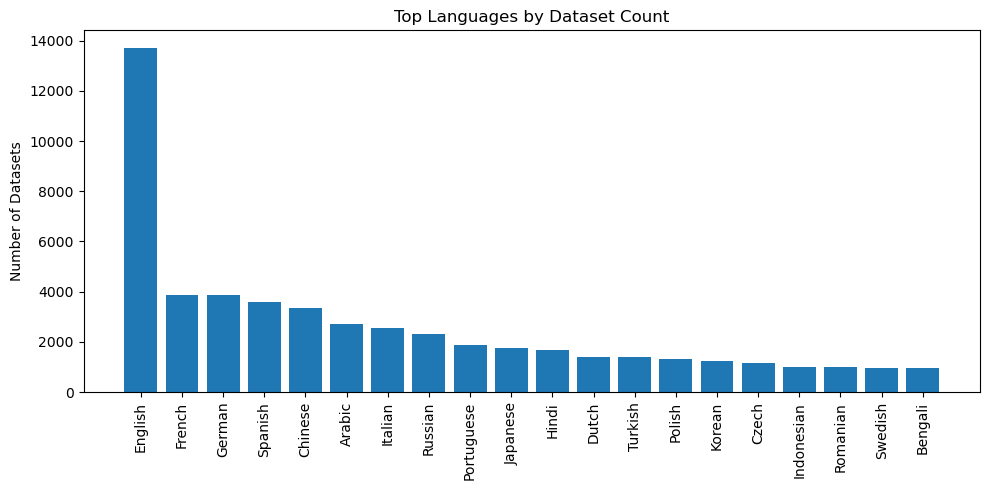

In [27]:
lang_counts = df_lang["language"].value_counts()

top_languages = lang_counts.head(20)

plt.figure(figsize=(10,5))
plt.bar(top_languages.index, top_languages.values)
plt.xticks(rotation=90)
plt.title("Top Languages by Dataset Count")
plt.ylabel("Number of Datasets")
plt.tight_layout()
plt.show()

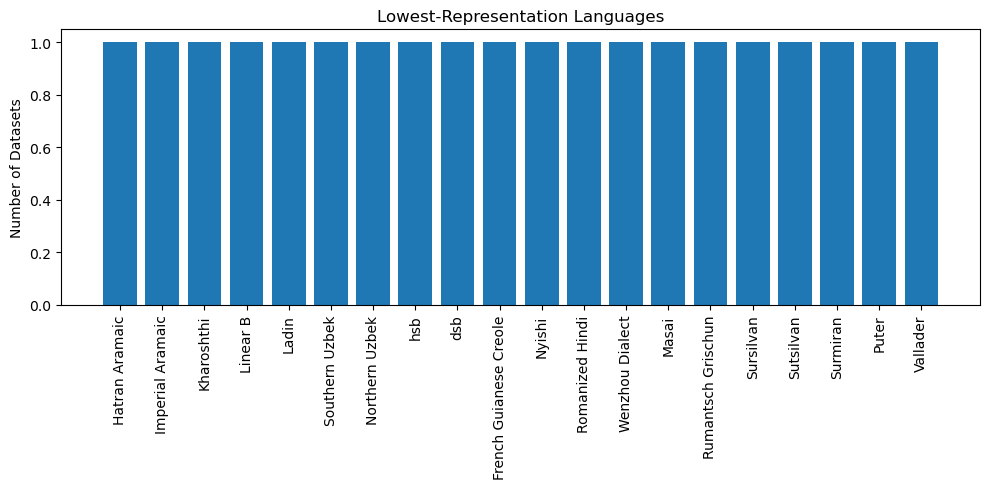

In [28]:
low_languages = lang_counts.tail(20)

plt.figure(figsize=(10,5))
plt.bar(low_languages.index, low_languages.values)
plt.xticks(rotation=90)
plt.title("Lowest-Representation Languages")
plt.ylabel("Number of Datasets")
plt.tight_layout()
plt.show()

### Number of languages

In [31]:
num_languages = df_lang["language"].nunique()
print("Total number of languages:", num_languages)

Total number of languages: 1588


### Country per language

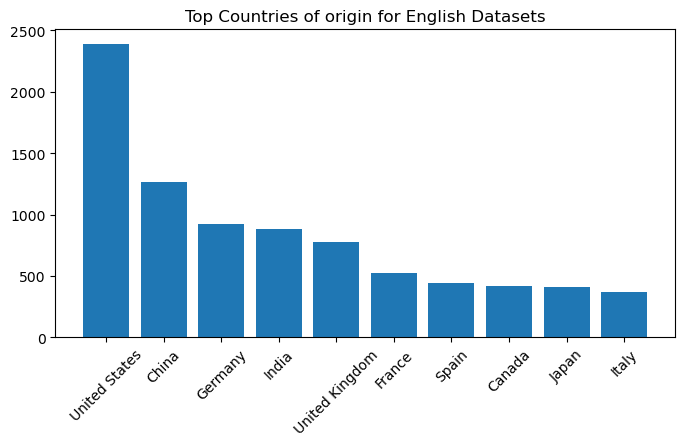

In [42]:
lang = "English"

subset = df_lang[df_lang["language"] == lang]

country_counts = subset["content_country"].value_counts().head(10)

plt.figure(figsize=(8,4))
plt.bar(country_counts.index, country_counts.values)
plt.xticks(rotation=45)
plt.title(f"Top Countries of origin for {lang} Datasets")
plt.show()

In [44]:
num = subset["content_country"].nunique()
print(f"{num} countries have {lang} datasets")

189 countries have English datasets


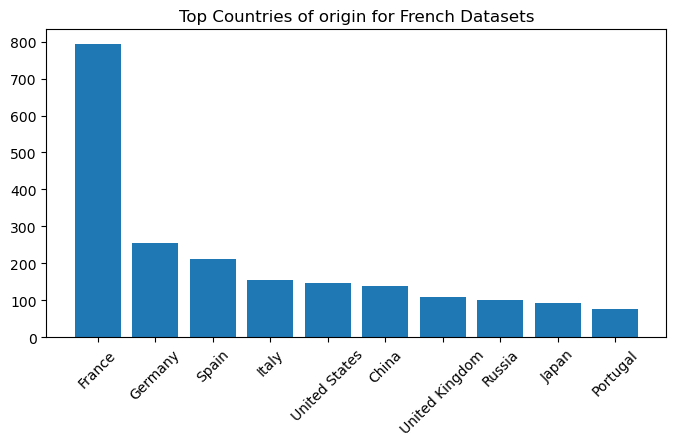

In [45]:
lang = "French"

subset = df_lang[df_lang["language"] == lang]

country_counts = subset["content_country"].value_counts().head(10)

plt.figure(figsize=(8,4))
plt.bar(country_counts.index, country_counts.values)
plt.xticks(rotation=45)
plt.title(f"Top Countries of origin for {lang} Datasets")
plt.show()

In [46]:
num = subset["content_country"].nunique()
print(f"{num} countries have {lang} datasets")

161 countries have French datasets


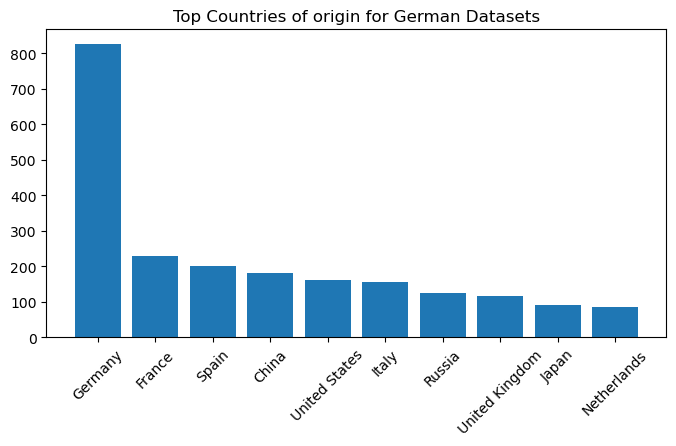

In [47]:
lang = "German"

subset = df_lang[df_lang["language"] == lang]

country_counts = subset["content_country"].value_counts().head(10)

plt.figure(figsize=(8,4))
plt.bar(country_counts.index, country_counts.values)
plt.xticks(rotation=45)
plt.title(f"Top Countries of origin for {lang} Datasets")
plt.show()

In [48]:
num = subset["content_country"].nunique()
print(f"{num} countries have {lang} datasets")

148 countries have German datasets


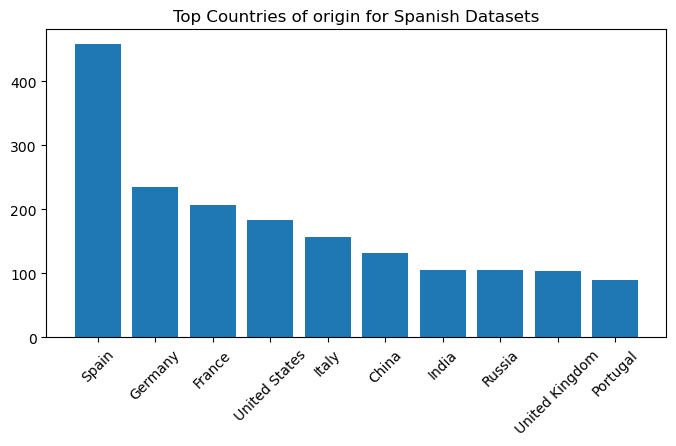

In [49]:
lang = "Spanish"

subset = df_lang[df_lang["language"] == lang]

country_counts = subset["content_country"].value_counts().head(10)

plt.figure(figsize=(8,4))
plt.bar(country_counts.index, country_counts.values)
plt.xticks(rotation=45)
plt.title(f"Top Countries of origin for {lang} Datasets")
plt.show()

In [50]:
num = subset["content_country"].nunique()
print(f"{num} countries have {lang} datasets")

144 countries have Spanish datasets


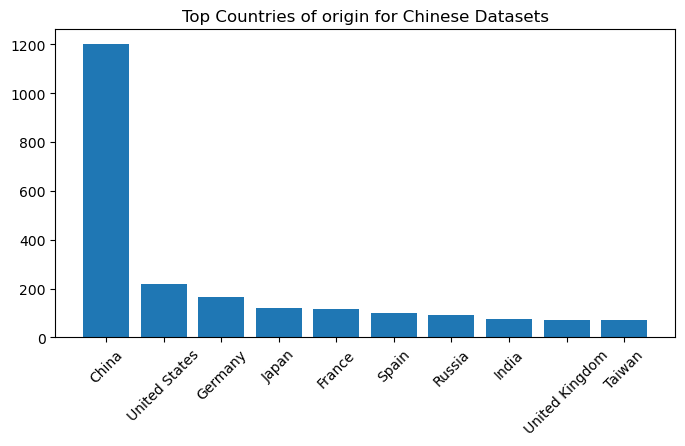

In [51]:
lang = "Chinese"

subset = df_lang[df_lang["language"] == lang]

country_counts = subset["content_country"].value_counts().head(10)

plt.figure(figsize=(8,4))
plt.bar(country_counts.index, country_counts.values)
plt.xticks(rotation=45)
plt.title(f"Top Countries of origin for {lang} Datasets")
plt.show()

In [52]:
num = subset["content_country"].nunique()
print(f"{num} countries have {lang} datasets")

130 countries have Chinese datasets


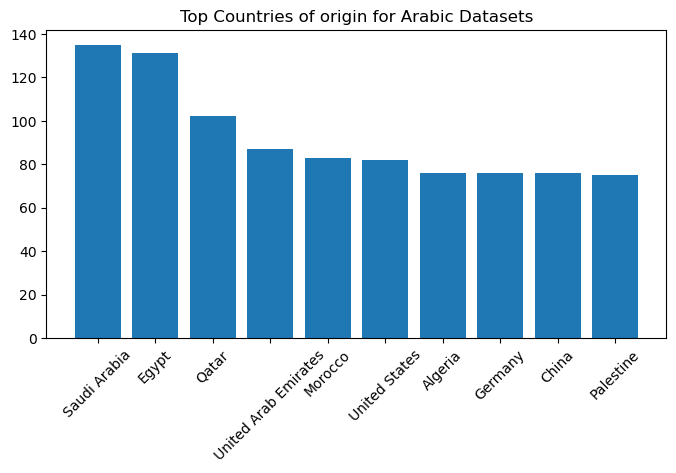

In [53]:
lang = "Arabic"

subset = df_lang[df_lang["language"] == lang]

country_counts = subset["content_country"].value_counts().head(10)

plt.figure(figsize=(8,4))
plt.bar(country_counts.index, country_counts.values)
plt.xticks(rotation=45)
plt.title(f"Top Countries of origin for {lang} Datasets")
plt.show()

In [54]:
num = subset["content_country"].nunique()
print(f"{num} countries have {lang} datasets")

157 countries have Arabic datasets


In [55]:
df_lang.groupby("Dataset name")["content_country"].nunique().describe()

count    11072.000000
mean         1.868768
std          3.381480
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        160.000000
Name: content_country, dtype: float64

In [56]:
df_filtered = df_lang.groupby("Dataset name").filter(
    lambda x: x["content_country"].nunique() <= 10
)

In [57]:
country_per_lang = (
    df_filtered.groupby("language")["content_country"]
    .nunique()
    .sort_values(ascending=False)
)

In [58]:
country_per_lang.head(20)

language
English       155
French        108
Spanish       101
Arabic         91
German         90
Russian        84
Chinese        77
Turkish        74
Italian        73
Japanese       72
Hindi          72
Portuguese     71
Swahili        65
Finnish        63
Polish         63
Croatian       62
Korean         62
Persian        62
Indonesian     59
Czech          57
Name: content_country, dtype: int64

In [59]:
df_lang_unique = df_lang.drop_duplicates(
    subset=["Dataset name", "content_country", "language"]
)

In [62]:
df_lang.groupby("Dataset name")["content_country"].nunique().sort_values(ascending=False).head(30)

Dataset name
AA Citation Corpus                                                            160
HateDefCon                                                                    108
MASSIVE                                                                        74
MM-Sum                                                                         67
Cheetah                                                                        53
AfroLID                                                                        53
Political Compass Test (PCT)                                                   50
Holocaust Survivor Testimonies                                                 49
Emotion Lexicons for 91 Languages                                              47
CURRICULUM benchmark                                                           40
WMT-2022: Large-Scale Machine Translation Evaluation for African Languages     37
OPUS-100                                                                       36
Soc